In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
# df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


I decided to cap the outlier in the study_hours with the maximum value from the other values of that column because replacing it with the maximum keeps the highness of that data in mind while still reducing its influence on the analysis. I also filled the NaN values with the median of that column. The attendance values were in floating numbers so I rounded up the column to the nearest whole integer. I also clipped these values to avoid negative values for study_hours and attendance.

In [2]:
max_of_rest = df.loc[df['study_hours'] < 50, 'study_hours'].max()
df.loc[df['study_hours'] == 50, 'study_hours'] = max_of_rest

clean_median = df['study_hours'].median()
df['study_hours'] = df['study_hours'].fillna(clean_median)

df['study_hours'] = df['study_hours'].clip(lower=0)
df['attendance'] = df['attendance'].clip(lower=0, upper=100)

df['attendance'] = df['attendance'].round(0).astype(int)

print(df)

    study_hours  attendance  previous_mark  final_score
0      4.812342          71      75.366810    35.178989
1      4.812342          81      78.411768    39.481248
2      4.812342          82      86.245769    48.605167
3      4.812342          77      85.807031    47.329456
4      4.812342          83      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970          89      59.606356    37.267830
96     5.592241          76      83.493998    33.777675
97     5.522111          87      74.609493    50.413491
98     5.010227           0      82.192932    44.045627
99     8.704556          74      79.444433    46.414470

[100 rows x 4 columns]


The shape of the feature matrix is 100x3. The numerical columns are study_hours, attendance, previous_mark and final_score. The target variable is final_score, because it is the score we want to predict. The other three columns are input features.

In [3]:

X = df[["study_hours", "attendance", "previous_mark"]]
y = df["final_score"]

print("Full dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nData types:")
print(df.dtypes)

Full dataset shape: (100, 4)
Feature matrix shape: (100, 3)
Target shape: (100,)

Data types:
study_hours      float64
attendance         int64
previous_mark    float64
final_score      float64
dtype: object


In [4]:
summary = df.agg(["mean", "median", "std"])
print(summary.round(3))

        study_hours  attendance  previous_mark  final_score
mean          4.784      84.010         70.973       42.692
median        4.812      86.000         71.465       42.763
std           1.812      12.148         16.264        6.087


- **Study hours**: The mean and median are close, suggesting that typical study time is centered around `4.7`–`4.8` hours after cleaning. The standard deviation is about `1.8`, indicating variation among students.
- **Attendance**: The average attendance is approximately `84%`, and the standard deviation is about `12.15`. This shows students vary in their attendance, but the average is still relatively high.
- **Previous marks and final scores**: Previous marks have a standard deviation of `16.26`, showing substantial differences in students' previous academic performance. Final scores vary less, with a standard deviation of about `6.09`.

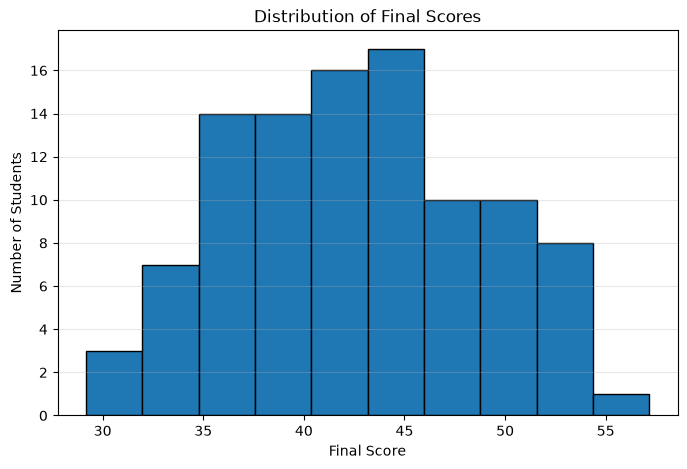

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["final_score"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)
plt.show()

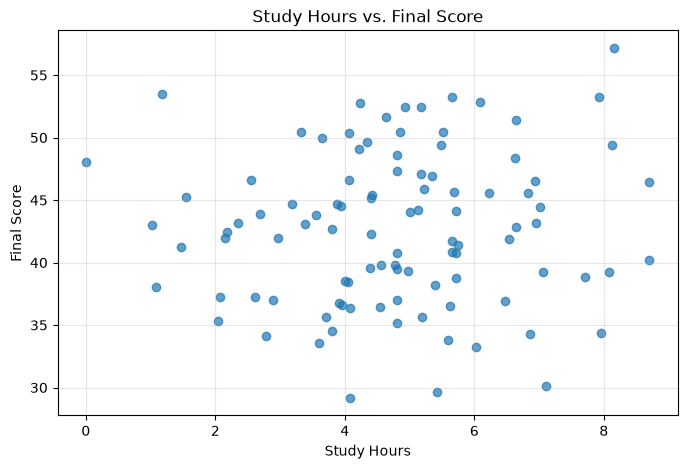

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["study_hours"],
    df["final_score"],
    alpha=0.7
)

plt.title("Study Hours vs. Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.grid(alpha=0.3)
plt.show()

The scatter plot shows a weak relationship between study hours and final scores. Students who studied for similar amounts of time achieved different scores. This suggests that study hours alone do not strongly explain students' final performance without other factors.

In [7]:
correlation = df["study_hours"].corr(df["final_score"])

print("Pearson correlation:", round(correlation, 4))

Pearson correlation: 0.0631


I got Pearson correlation coefficient of **0.0631** which indicates a very weak positive linear relationship between study hours and final score in this dataset.

**If a student studies 10 hours, does the correlation guarantee a specific score?**
No. Correlation doesn't guarantee an individual outcome. Two students who study for 10hrs may receive different scores. A potential confounding variable is previous academic performance. Students who already have stronger academic foundations might both study differently and achieve higher final scores.

In [8]:
# Select one student's three input features
x = df.loc[6, ["study_hours", "attendance", "previous_mark"]].to_numpy()

w = np.array([0.5, 0.2, 0.4])
b = 5

prediction = np.dot(w, x) + b

print("Student vector:", x)
print("Weight vector:", w)
print("Dot product:", np.dot(w, x))
print("Prediction:", prediction)


Student vector: [  8.15842563 100.          77.72552901]
Weight vector: [0.5 0.2 0.4]
Dot product: 55.16942441875935
Prediction: 60.16942441875935


- **Weights(w)**: Each weight represents the coefficient assigned to an input feature.
- **Bias(b)**: The bias is the model's baseline adjustment. It allows the prediction to be shifted up or down independently of the input values. Without a bias, the model's prediction would always be zero when all input features are zero.

In [9]:
scaled_df = df.copy()

columns_to_scale = ["study_hours", "previous_mark"]

for col in columns_to_scale:
    mean = df[col].mean()
    std = df[col].std()

    scaled_df[col] = (df[col] - mean) / std

print(scaled_df[columns_to_scale].head())

print("\nMeans after standardization:")
print(scaled_df[columns_to_scale].mean().round(6))

print("\nStandard deviations after standardization:")
print(scaled_df[columns_to_scale].std().round(6))


   study_hours  previous_mark
0     0.015662       0.270124
1     0.015662       0.457342
2     0.015662       0.939012
3     0.015662       0.912037
4     0.015662      -1.330433

Means after standardization:
study_hours     -0.0
previous_mark    0.0
dtype: float64

Standard deviations after standardization:
study_hours      1.0
previous_mark    1.0
dtype: float64


## Why does K-Nearest Neighbors need scaling?
K-Nearest Neighbors (KNN) identifies nearby observations by calculating distances between feature vectors. If the features have very different numerical ranges, the larger-scale feature can dominate those distances.

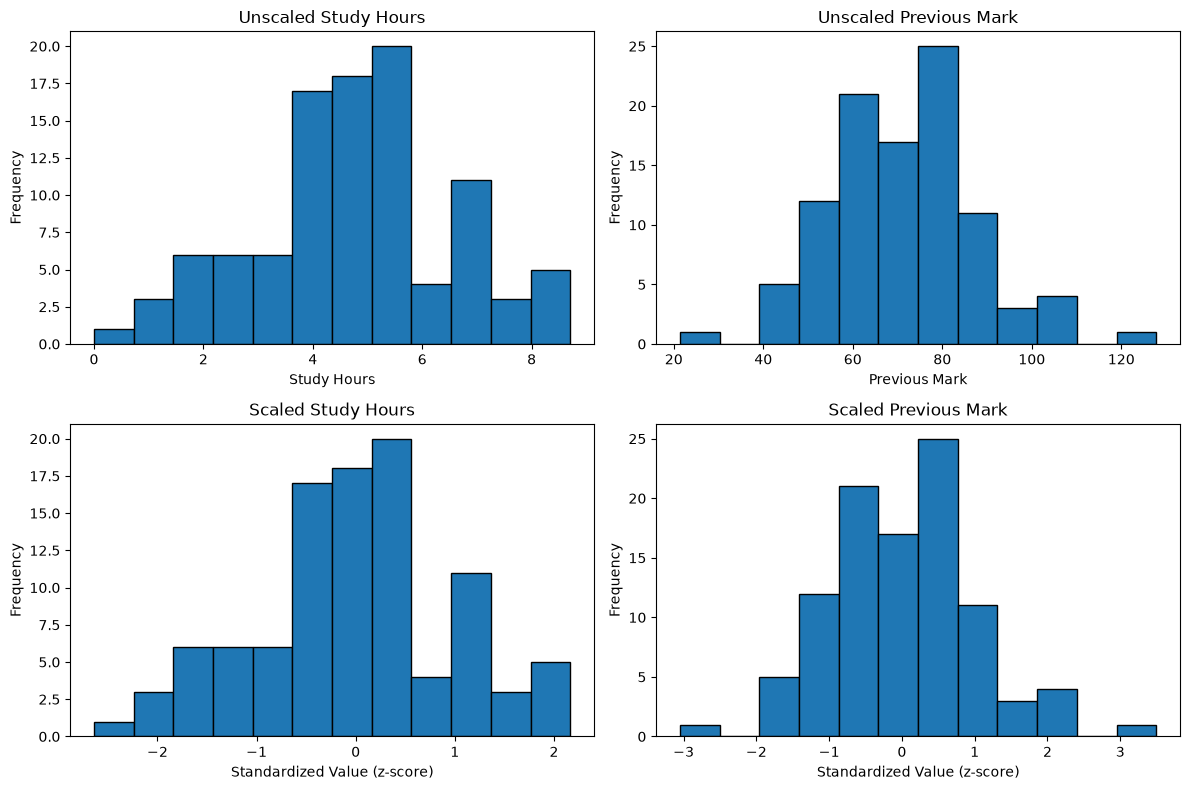

In [10]:
features = ["study_hours", "previous_mark"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Original distributions
axes[0, 0].hist(df["study_hours"], bins=12, edgecolor="black")
axes[0, 0].set_title("Unscaled Study Hours")
axes[0, 0].set_xlabel("Study Hours")
axes[0, 0].set_ylabel("Frequency")

axes[0, 1].hist(df["previous_mark"], bins=12, edgecolor="black")
axes[0, 1].set_title("Unscaled Previous Mark")
axes[0, 1].set_xlabel("Previous Mark")
axes[0, 1].set_ylabel("Frequency")

# Standardized distributions
axes[1, 0].hist(scaled_df["study_hours"], bins=12, edgecolor="black")
axes[1, 0].set_title("Scaled Study Hours")
axes[1, 0].set_xlabel("Standardized Value (z-score)")
axes[1, 0].set_ylabel("Frequency")

axes[1, 1].hist(scaled_df["previous_mark"], bins=12, edgecolor="black")
axes[1, 1].set_title("Scaled Previous Mark")
axes[1, 1].set_xlabel("Standardized Value (z-score)")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


Without scaling, K-Nearest Neighbors may produce misleading results because it calculates distances between data points. The `study_hours` feature has a much smaller range (approximately 0–9) than `previous_mark` (approximately 30–120). Therefore, differences in previous marks may dominate the distance calculation, causing KNN to give more importance to that feature. Standardization puts both features on a comparable scale so that neither dominates simply because of its numerical range.